# Notebook 47 — STA1 Metadata Analysis\n\nCross-tabulation of TP-P20 two-tier metrics against STA1 metadata fields:\n- `$I` = illustration type (H/A/B/C/P/S/T/Z)\n- `$L` = Currier language (A/B)\n- `$H` = writing hand (1–5, @)\n\nGoal: determine whether syllabic structure varies systematically with metadata.

In [56]:
# Cell 1 — Imports
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict
from scipy.stats import chi2_contingency
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist

sns.set_style("whitegrid")
print("Imports OK")

Imports OK


In [57]:
# Cell 2 — Parse STA1 corpus
# folio_data[folio] = {'meta': {'I': ..., 'L': ..., 'H': ...}, 'words': [[glyph_pair, ...], ...]}

STA_PATH = "corpus/voynich_sta.txt"

folio_data = {}
current_folio = None

with open(STA_PATH, "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue

        # Header line: <f1r>  <! $Q=A $P=A ... $I=T $L=A $H=1 ...>
        hdr_match = re.match(r"^<([^>]+)>\s+<!", line)
        if hdr_match:
            current_folio = hdr_match.group(1)
            meta = {}
            for key in ("I", "L", "H"):
                m = re.search(rf"\$({key})=(\S+)", line)
                if m:
                    meta[key] = m.group(2)
            folio_data[current_folio] = {"meta": meta, "words": []}
            continue

        # Text line: <f1r.1,@P0>  P2A3K1A2C2.A2Q1A3B2...
        txt_match = re.match(r"^<[^>]+>\s+(.*)", line)
        if txt_match and current_folio:
            text_part = txt_match.group(1)
            # Remove inline comments {…} and gap markers <->
            text_part = re.sub(r"\{[^}]*\}", "", text_part)
            text_part = re.sub(r"<->", ".", text_part)
            # Split into word chunks by '.' and '-'
            chunks = re.split(r"[.\-]", text_part)
            for chunk in chunks:
                chunk = chunk.strip().rstrip(",")
                if not chunk:
                    continue
                glyphs = re.findall(r"[A-Z][0-9a-z]", chunk)
                if glyphs:
                    folio_data[current_folio]["words"].append(glyphs)

# Summary
n_folios = len(folio_data)
n_words = sum(len(fd["words"]) for fd in folio_data.values())
n_glyphs = sum(len(w) for fd in folio_data.values() for w in fd["words"])

print(f"Folios: {n_folios}")
print(f"Words:  {n_words}")
print(f"Glyphs: {n_glyphs}")
print(f"Distinct glyphs: {len(set(g for fd in folio_data.values() for w in fd['words'] for g in w))}")
print()

# Metadata distributions
for key in ("I", "L", "H"):
    counts = Counter(fd["meta"].get(key, "?") for fd in folio_data.values())
    print(f"${key} distribution (folios): {dict(sorted(counts.items()))}")

print()
for key in ("I", "L", "H"):
    counts = Counter()
    for fd in folio_data.values():
        val = fd["meta"].get(key, "?")
        counts[val] += len(fd["words"])
    print(f"${key} distribution (words):  {dict(sorted(counts.items()))}")

Folios: 227
Words:  37848
Glyphs: 157254
Distinct glyphs: 166

$I distribution (folios): {'A': 8, 'B': 19, 'C': 11, 'H': 129, 'P': 16, 'S': 25, 'T': 7, 'Z': 12}
$L distribution (folios): {'?': 30, 'A': 114, 'B': 83}
$H distribution (folios): {'1': 94, '1>': 19, '2': 46, '3': 15, '3>': 18, '4': 13, '4>': 14, '5': 6, '5>': 1, '@>': 1}

$I distribution (words):  {'A': 839, 'B': 6276, 'C': 2180, 'H': 11128, 'P': 2533, 'S': 11341, 'T': 2300, 'Z': 1251}
$L distribution (words):  {'?': 3179, 'A': 11178, 'B': 23491}
$H distribution (words):  {'1': 7921, '1>': 2712, '2': 10934, '3': 4022, '3>': 7447, '4': 1771, '4>': 1687, '5': 791, '5>': 111, '@>': 452}


In [58]:
# Cell 3 — Metadata cross-tabulations

# Build a DataFrame with one row per folio
rows = []
for folio, fd in folio_data.items():
    rows.append({
        "folio": folio,
        "I": fd["meta"].get("I", "?"),
        "L": fd["meta"].get("L", "?"),
        "H": fd["meta"].get("H", "?"),
        "n_words": len(fd["words"]),
    })
df_folios = pd.DataFrame(rows)

print("=== $I x $L (folio counts) ===")
ct_IL = pd.crosstab(df_folios["I"].astype(str), df_folios["L"].astype(str), margins=True)
print(ct_IL)
print()

print("=== $I x $H (folio counts) ===")
ct_IH = pd.crosstab(df_folios["I"].astype(str), df_folios["H"].astype(str), margins=True)
print(ct_IH)
print()

print("=== $L x $H (folio counts) ===")
ct_LH = pd.crosstab(df_folios["L"].astype(str), df_folios["H"].astype(str), margins=True)
print(ct_LH)
print()

print("=== Word counts by $I ===")
wc_I = df_folios.groupby("I")["n_words"].sum().sort_values(ascending=False)
print(wc_I)
print(f"\nTotal words: {wc_I.sum()}")

=== $I x $L (folio counts) ===
L     ?    A   B  All
I                    
A     8    0   0    8
B     0    0  19   19
C     7    0   4   11
H     2   95  32  129
P     0   16   0   16
S     0    2  23   25
T     1    1   5    7
Z    12    0   0   12
All  30  114  83  227

=== $I x $H (folio counts) ===
H     1  1>   2   3  3>   4  4>  5  5>  @>  All
I                                              
A     0   0   0   0   0   0   8  0   0   0    8
B     0   0  19   0   0   0   0  0   0   0   19
C     0   1   3   0   0   1   6  0   0   0   11
H    91   4  20   6   2   0   0  5   1   0  129
P     2  14   0   0   0   0   0  0   0   0   16
S     0   0   0   8  16   0   0  0   0   1   25
T     1   0   4   1   0   0   0  1   0   0    7
Z     0   0   0   0   0  12   0  0   0   0   12
All  94  19  46  15  18  13  14  6   1   1  227

=== $L x $H (folio counts) ===
H     1  1>   2   3  3>   4  4>  5  5>  @>  All
L                                              
?     0   1   0   1   2  12  14  0   0 

In [59]:
# Cell 4 — Standard TP-P20 pipeline (identical to notebooks 36-44)

# Collect all words (already lists of glyph pairs)
all_words = [w for fd in folio_data.values() for w in fd['words']]
VOCAB = sorted(set(g for w in all_words for g in w))
print(f'Vocabulary: {len(VOCAB)} glyph types, {len(all_words):,} words')

# Build transition matrix
idx_map = {g: i for i, g in enumerate(VOCAB)}
nv = len(VOCAB)
M = np.zeros((nv, nv))
for w in all_words:
    for i in range(len(w)-1):
        M[idx_map[w[i]], idx_map[w[i+1]]] += 1
rs = M.sum(axis=1, keepdims=True)
rs[rs == 0] = 1
M_prob = M / rs

# TP threshold at P20
all_tp = []
for w in all_words:
    for i in range(len(w)-1):
        all_tp.append(M_prob[idx_map[w[i]], idx_map[w[i+1]]])
thr = np.percentile(all_tp, 20)
print(f'TP threshold (P20): {thr:.4f}')

# Segment words into syllables
def segment(w):
    syls, s = [], [w[0]]
    for i in range(len(w)-1):
        p = M_prob[idx_map[w[i]], idx_map[w[i+1]]] if (w[i] in idx_map and w[i+1] in idx_map) else 0
        if p < thr:
            syls.append(tuple(s))
            s = [w[i+1]]
        else:
            s.append(w[i+1])
    if s:
        syls.append(tuple(s))
    return syls

# Classify syllables positionally
syl_pos = defaultdict(lambda: {'s':0, 'm':0, 'e':0, 't':0})
for w in all_words:
    syls = segment(w)
    ns = len(syls)
    for i, syl in enumerate(syls):
        syl_pos[syl]['t'] += 1
        if ns == 1:
            syl_pos[syl]['s'] += 1
            syl_pos[syl]['e'] += 1
        elif i == 0:
            syl_pos[syl]['s'] += 1
        elif i == ns - 1:
            syl_pos[syl]['e'] += 1
        else:
            syl_pos[syl]['m'] += 1

clase = {}
for syl, c in syl_pos.items():
    if c['t'] < 5:
        continue
    r_s = c['s'] / c['t']
    r_e = c['e'] / c['t']
    r_m = c['m'] / c['t']
    if r_s >= 0.6 and r_e < 0.3:
        clase[syl] = 'onset'
    elif r_e >= 0.6 and r_s < 0.3:
        clase[syl] = 'coda'
    elif r_m >= 0.4:
        clase[syl] = 'nuclear'
    else:
        clase[syl] = 'free'

n_o = sum(1 for v in clase.values() if v == 'onset')
n_n = sum(1 for v in clase.values() if v == 'nuclear')
n_c = sum(1 for v in clase.values() if v == 'coda')
n_f = sum(1 for v in clase.values() if v == 'free')
print(f'Syllable types: {len(clase)} (O={n_o}, N={n_n}, C={n_c}, F={n_f})')

# Tier assignment
def word_tier(w):
    syls = segment(w)
    pat = '-'.join(clase.get(s, '?') for s in syls)
    abbr = pat.replace('onset','O').replace('nuclear','N').replace('coda','C').replace('free','F')
    if '?' in abbr:
        return '?', abbr
    if abbr == 'F':
        return 'T1', abbr
    return 'T2', abbr

tier_counts = Counter()
for w in all_words:
    t, _ = word_tier(w)
    tier_counts[t] += 1
print(f'Tier distribution: {dict(tier_counts)}')

# Build per-word onset glyph and metadata labels (needed by later cells)
word_onset_glyph = []
word_I_labels = []
word_L_labels = []
word_H_labels = []

for folio, fd in folio_data.items():
    itype = fd['meta'].get('I', '?')
    lang = fd['meta'].get('L', '?')
    hand = fd['meta'].get('H', '?')
    for w in fd['words']:
        syls = segment(w)
        first_onset = None
        for syl in syls:
            if clase.get(syl) == 'onset':
                first_onset = syl
                break
        word_onset_glyph.append(first_onset)
        word_I_labels.append(itype)
        word_L_labels.append(lang)
        word_H_labels.append(hand)

print(f'Words with onset: {sum(1 for o in word_onset_glyph if o is not None):,}')

# Pre-compute tier for each word
word_tiers = [word_tier(w)[0] for w in all_words]


Vocabulary: 166 glyph types, 37,848 words
TP threshold (P20): 0.0902
Syllable types: 773 (O=165, N=49, C=88, F=471)
Tier distribution: {'T2': 18246, 'T1': 16894, '?': 2708}
Words with onset: 14,230


In [60]:
# Cell 5 — Two-tier metrics by $I type

def compute_twotier_metrics(words):
    """Compute standard two-tier metrics for a word list."""
    if not words:
        return {'n_words': 0, 'pct_F': 0, 'pct_OC': 0, 'utilisation': 0, 'oc_ratio': 0}
    
    patterns = Counter()
    for w in words:
        t, pat = word_tier(w)
        if '?' not in pat:
            patterns[pat] += 1
    
    total = sum(patterns.values())
    if total == 0:
        return {'n_words': len(words), 'pct_F': 0, 'pct_OC': 0, 'utilisation': 0, 'oc_ratio': 0}
    
    pct_F = patterns.get('F', 0) / total
    pct_OC = patterns.get('O-C', 0) / total
    
    # O-C utilisation
    oc_combos = Counter()
    for w in words:
        syls = segment(w)
        if len(syls) == 2:
            c1 = clase.get(syls[0])
            c2 = clase.get(syls[1])
            if c1 == 'onset' and c2 == 'coda':
                oc_combos[(syls[0], syls[1])] += 1
    
    n_onsets = len(set(o for o, c in oc_combos))
    n_codas = len(set(c for o, c in oc_combos))
    possible = n_onsets * n_codas if n_onsets and n_codas else 1
    utilisation = len(oc_combos) / possible
    
    # Onset/coda ratio (from syllable classification, not from O-C pairs)
    all_onset_types = set()
    all_coda_types = set()
    for w in words:
        for syl in segment(w):
            c = clase.get(syl)
            if c == 'onset':
                all_onset_types.add(syl)
            elif c == 'coda':
                all_coda_types.add(syl)
    
    oc_ratio = len(all_onset_types) / len(all_coda_types) if all_coda_types else 0
    
    return {
        'n_words': len(words),
        'pct_F': round(pct_F, 3),
        'pct_OC': round(pct_OC, 3),
        'utilisation': round(utilisation, 3),
        'oc_ratio': round(oc_ratio, 2),
        'n_oc_observed': len(oc_combos),
    }

# Group words by $I type
words_by_I = defaultdict(list)
for folio, fd in folio_data.items():
    itype = fd['meta'].get('I', '?')
    words_by_I[itype].extend(fd['words'])

type_names = {'H':'Herbal','A':'Astronomical','B':'Biological','C':'Cosmological',
              'P':'Pharmaceutical','S':'Stars only','T':'Text-only','Z':'Zodiac'}

metrics_by_I = {}
print('=== Two-tier metrics by illustration type ($I) ===')
print(f'{"":<16} {"%F":<8} {"%OC":<8} {"Util%":<8} {"O/C":<6} {"Words":<7}')
print('-' * 55)
for t in ['H','B','P','S','Z','A','C','T']:
    if t in words_by_I:
        m = compute_twotier_metrics(words_by_I[t])
        metrics_by_I[t] = m
        print(f'{type_names.get(t,t):<16} {m["pct_F"]*100:<8.1f} {m["pct_OC"]*100:<8.1f} '
              f'{m["utilisation"]*100:<8.1f} {m["oc_ratio"]:<6.2f} {m["n_words"]}')


=== Two-tier metrics by illustration type ($I) ===
                 %F       %OC      Util%    O/C    Words  
-------------------------------------------------------
Herbal           42.1     15.9     5.8      1.82   11128
Biological       61.9     13.9     5.9      1.67   6276
Pharmaceutical   41.7     18.0     6.1      1.55   2533
Stars only       51.1     17.2     5.7      1.80   11341
Zodiac           36.0     21.5     6.0      1.59   1251
Astronomical     27.6     20.4     5.7      1.70   839
Cosmological     40.1     19.3     5.1      1.66   2180
Text-only        51.1     17.3     4.4      1.98   2300


In [61]:
# Cell 6 — Two-tier metrics by Currier language ($L)

words_by_L = defaultdict(list)
for folio, fd in folio_data.items():
    ltype = fd["meta"].get("L", "?")
    words_by_L[ltype].extend(fd["words"])

metrics_by_L = {}
for ltype in sorted(words_by_L.keys()):
    metrics_by_L[ltype] = compute_twotier_metrics(words_by_L[ltype])

df_L = pd.DataFrame(metrics_by_L).T
df_L.index.name = "$L"
print("=== Two-tier metrics by Currier language ($L) ===")
print(df_L.to_string())

=== Two-tier metrics by Currier language ($L) ===
    n_words  pct_F  pct_OC  utilisation  oc_ratio  n_oc_observed
$L                                                              
?    3179.0  0.344   0.203        0.053      1.74          259.0
A   11178.0  0.418   0.148        0.061      1.82          457.0
B   23491.0  0.528   0.170        0.063      1.85          726.0


In [62]:
# Cell 7 — Two-tier metrics by writing hand ($H)

words_by_H = defaultdict(list)
for folio, fd in folio_data.items():
    htype = fd["meta"].get("H", "?")
    words_by_H[htype].extend(fd["words"])

metrics_by_H = {}
for htype in sorted(words_by_H.keys()):
    metrics_by_H[htype] = compute_twotier_metrics(words_by_H[htype])

df_H = pd.DataFrame(metrics_by_H).T
df_H.index.name = "$H"
print("=== Two-tier metrics by writing hand ($H) ===")
print(df_H.to_string())

=== Two-tier metrics by writing hand ($H) ===
    n_words  pct_F  pct_OC  utilisation  oc_ratio  n_oc_observed
$H                                                              
1    7921.0  0.412   0.139        0.064      1.85          354.0
1>   2712.0  0.423   0.165        0.060      1.62          194.0
2   10934.0  0.566   0.163        0.050      1.78          461.0
3    4022.0  0.480   0.186        0.056      1.75          296.0
3>   7447.0  0.523   0.167        0.053      1.88          403.0
4    1771.0  0.360   0.199        0.053      1.68          167.0
4>   1687.0  0.321   0.208        0.052      1.71          175.0
5     791.0  0.387   0.203        0.062      2.08           97.0
5>    111.0  0.302   0.226        0.146      2.69           21.0
@>    452.0  0.474   0.181        0.077      1.86           57.0


In [63]:
# Cell 8 — Onset family x $I type

# Build onset-coda co-occurrence vectors for onset glyphs
onset_glyphs = [g for g, r in clase.items() if r == 'onset']
coda_glyphs = [g for g, r in clase.items() if r == 'coda']

if len(onset_glyphs) >= 2 and len(coda_glyphs) >= 1:
    # For each onset glyph, count which coda glyphs follow it within the same word
    coda_idx = {g: i for i, g in enumerate(sorted(coda_glyphs))}
    onset_vectors = {}
    for og in onset_glyphs:
        vec = np.zeros(len(coda_glyphs))
        for w in all_words:
            for i, g in enumerate(w):
                if g == og:
                    # Look for coda glyphs later in the word
                    for j in range(i + 1, len(w)):
                        if w[j] in coda_idx:
                            vec[coda_idx[w[j]]] += 1
        onset_vectors[og] = vec

    # Cluster onsets
    onset_list = sorted(onset_vectors.keys())
    X = np.array([onset_vectors[g] for g in onset_list])

    # Normalize rows
    row_norms = X.sum(axis=1, keepdims=True)
    row_norms[row_norms == 0] = 1
    X_norm = X / row_norms

    n_clusters = min(12, len(onset_list))
    if len(onset_list) > 1:
        dist_matrix = pdist(X_norm, metric="cosine")
        dist_matrix = np.nan_to_num(dist_matrix, nan=1.0)
        Z = linkage(dist_matrix, method="average")
        labels = fcluster(Z, t=n_clusters, criterion="maxclust")
    else:
        labels = np.array([1])

    onset_family = {g: int(labels[i]) for i, g in enumerate(onset_list)}
    print(f"Onset glyphs: {len(onset_list)}, clustered into {len(set(labels))} families")

    # Assign each word its onset family
    word_onset_family = []
    for og in word_onset_glyph:
        if og is not None and og in onset_family:
            word_onset_family.append(onset_family[og])
        else:
            word_onset_family.append(None)

    # Build word-level $I labels (aligned with all_words)
    word_I_labels = []
    for folio, fd in folio_data.items():
        itype = fd["meta"].get("I", "?")
        word_I_labels.extend([itype] * len(fd["words"]))

    # Cross-tab onset_family x $I (only words with an onset)
    rows_fam_I = []
    for i, (fam, itype) in enumerate(zip(word_onset_family, word_I_labels)):
        if fam is not None:
            rows_fam_I.append({"family": fam, "I": itype})

    df_fam_I = pd.DataFrame(rows_fam_I)
    ct_fam_I = pd.crosstab(df_fam_I["family"].astype(str), df_fam_I["I"].astype(str))
    print("\n=== Onset family x $I (word counts) ===")
    print(ct_fam_I)

    # Chi-squared test
    chi2_fam_I, p_fam_I, dof_fam_I, _ = chi2_contingency(ct_fam_I.values)
    print(f"\nChi2 = {chi2_fam_I:.2f}, dof = {dof_fam_I}, p = {p_fam_I:.4e}")
else:
    print("Not enough onset/coda glyphs for clustering")
    chi2_fam_I, p_fam_I, dof_fam_I = 0.0, 1.0, 0
    onset_family = {}
    word_onset_family = [None] * len(all_words)
    word_I_labels = []
    for folio, fd in folio_data.items():
        itype = fd["meta"].get("I", "?")
        word_I_labels.extend([itype] * len(fd["words"]))

Onset glyphs: 165, clustered into 1 families

=== Onset family x $I (word counts) ===
I         A     B     C     H     P     S    T    Z
family                                             
1       479  1568  1003  4486  1036  4231  820  607

Chi2 = 0.00, dof = 0, p = 1.0000e+00


In [64]:
# Cell 9 — Onset family x Currier language ($L)

# Build word-level $L labels
word_L_labels = []
for folio, fd in folio_data.items():
    ltype = fd["meta"].get("L", "?")
    word_L_labels.extend([ltype] * len(fd["words"]))

rows_fam_L = []
for fam, ltype in zip(word_onset_family, word_L_labels):
    if fam is not None:
        rows_fam_L.append({"family": fam, "L": ltype})

df_fam_L = pd.DataFrame(rows_fam_L)
ct_fam_L = pd.crosstab(df_fam_L["family"].astype(str), df_fam_L["L"].astype(str))
print("=== Onset family x $L (word counts) ===")
print(ct_fam_L)

chi2_fam_L, p_fam_L, dof_fam_L, _ = chi2_contingency(ct_fam_L.values)
print(f"\nChi2 = {chi2_fam_L:.2f}, dof = {dof_fam_L}, p = {p_fam_L:.4e}")

=== Onset family x $L (word counts) ===
L          ?     A     B
family                  
1       1577  4440  8213

Chi2 = 0.00, dof = 0, p = 1.0000e+00


In [65]:
# Cell 10 — First-T2 identifier uniqueness by $I

# For each folio, get its first T2 word as identifier
folio_identifiers = {}
for folio, fd in folio_data.items():
    itype = fd['meta'].get('I', '?')
    for w in fd['words']:
        t, pat = word_tier(w)
        if t == 'T2':
            # Convert to string for comparison
            w_str = '.'.join(w)
            folio_identifiers[folio] = {'word': w_str, 'I': itype}
            break

# Uniqueness by $I type
type_names = {'H':'Herbal','A':'Astronomical','B':'Biological','C':'Cosmological',
              'P':'Pharmaceutical','S':'Stars only','T':'Text-only','Z':'Zodiac'}

print('=== First-T2 identifier uniqueness by $I ===')
print(f'{"Type":<16} {"Folios":<8} {"Unique":<8} {"Ratio":<8}')
print('-' * 42)

id_uniqueness = {}
for itype in ['H','B','P','S','Z','A','C','T']:
    entries = [(f, info) for f, info in folio_identifiers.items() 
               if info['I'] == itype]
    if not entries:
        continue
    words = [info['word'] for _, info in entries]
    n_total = len(words)
    n_unique = len(set(words))
    ratio = n_unique / n_total if n_total > 0 else 0
    id_uniqueness[itype] = {'n_folios': n_total, 'n_unique': n_unique, 'ratio': round(ratio, 3)}
    print(f'{type_names.get(itype,itype):<16} {n_total:<8} {n_unique:<8} {ratio:<8.1%}')

# Chi-squared: are identifiers more unique in some $I types than others?
# Use a simpler approach: compare uniqueness ratios
print(f"\nOverall: {len(folio_identifiers)} folios with identifiers, "
      f"{len(set(info['word'] for info in folio_identifiers.values()))} unique")


=== First-T2 identifier uniqueness by $I ===
Type             Folios   Unique   Ratio   
------------------------------------------
Herbal           129      127      98.4%   
Biological       19       19       100.0%  
Pharmaceutical   16       16       100.0%  
Stars only       25       25       100.0%  
Zodiac           12       12       100.0%  
Astronomical     8        8        100.0%  
Cosmological     11       11       100.0%  
Text-only        6        6        100.0%  

Overall: 226 folios with identifiers, 223 unique


In [66]:
# Cell 11 — Community x metadata

# Load community assignments (folio -> community)
with open("resultados/vocabulary_network_resultados.json", "r") as f:
    vn_data = json.load(f)

folio_communities = vn_data.get("folio_communities", {})
print(f"Folios with community assignments: {len(folio_communities)}")
print(f"Community IDs: {sorted(set(folio_communities.values()))}")

# Build word-level community labels
word_comm_labels = []
word_H_labels = []
for folio, fd in folio_data.items():
    comm = folio_communities.get(folio, None)
    htype = fd["meta"].get("H", "?")
    for _ in fd["words"]:
        word_comm_labels.append(comm)
        word_H_labels.append(htype)

# --- Community x $I ---
rows_ci = []
for comm, itype in zip(word_comm_labels, word_I_labels):
    if comm is not None:
        rows_ci.append({"community": comm, "I": itype})

chi2_comm_I, p_comm_I, dof_comm_I = 0.0, 1.0, 0
chi2_comm_L, p_comm_L, dof_comm_L = 0.0, 1.0, 0
chi2_comm_H, p_comm_H, dof_comm_H = 0.0, 1.0, 0

if rows_ci:
    df_ci = pd.DataFrame(rows_ci)
    ct_comm_I = pd.crosstab(df_ci["community"].astype(str), df_ci["I"].astype(str))
    # Filter: only communities with >= 50 words
    ct_comm_I = ct_comm_I[ct_comm_I.sum(axis=1) >= 50]
    if ct_comm_I.shape[0] >= 2 and ct_comm_I.shape[1] >= 2:
        chi2_comm_I, p_comm_I, dof_comm_I, _ = chi2_contingency(ct_comm_I.values)
    print("=== Community x $I ===")
    print(ct_comm_I)
    print(f"Chi2 = {chi2_comm_I:.2f}, dof = {dof_comm_I}, p = {p_comm_I:.4e}\n")

# --- Community x $L ---
rows_cl = []
for comm, ltype in zip(word_comm_labels, word_L_labels):
    if comm is not None:
        rows_cl.append({"community": comm, "L": ltype})

if rows_cl:
    df_cl = pd.DataFrame(rows_cl)
    ct_comm_L = pd.crosstab(df_cl["community"].astype(str), df_cl["L"].astype(str))
    ct_comm_L = ct_comm_L[ct_comm_L.sum(axis=1) >= 50]
    if ct_comm_L.shape[0] >= 2 and ct_comm_L.shape[1] >= 2:
        chi2_comm_L, p_comm_L, dof_comm_L, _ = chi2_contingency(ct_comm_L.values)
    print("=== Community x $L ===")
    print(ct_comm_L)
    print(f"Chi2 = {chi2_comm_L:.2f}, dof = {dof_comm_L}, p = {p_comm_L:.4e}\n")

# --- Community x $H ---
rows_ch = []
for comm, htype in zip(word_comm_labels, word_H_labels):
    if comm is not None:
        rows_ch.append({"community": comm, "H": htype})

if rows_ch:
    df_ch = pd.DataFrame(rows_ch)
    ct_comm_H = pd.crosstab(df_ch["community"].astype(str), df_ch["H"].astype(str))
    ct_comm_H = ct_comm_H[ct_comm_H.sum(axis=1) >= 50]
    if ct_comm_H.shape[0] >= 2 and ct_comm_H.shape[1] >= 2:
        chi2_comm_H, p_comm_H, dof_comm_H, _ = chi2_contingency(ct_comm_H.values)
    print("=== Community x $H ===")
    print(ct_comm_H)
    print(f"Chi2 = {chi2_comm_H:.2f}, dof = {dof_comm_H}, p = {p_comm_H:.4e}")

Folios with community assignments: 225
Community IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
=== Community x $I ===
I            A     B    C     H     P      S     T    Z
community                                              
0            0     0    0  5697     0      0     0    0
1          352     0  979  2308  2533      0   206  807
10           0     0   61     0     0      0     0    0
11          65     0    0     0     0      0     0    0
12          80     0    0     0     0      0     0    0
13          97     0    0     0     0      0     0    0
14           0     0    0     0     0      0     0   99
15           0     0    0     0     0      0     0  154
16           0     0    0     0     0      0     0   96
17           0     0    0     0     0      0     0   95
18           0     0    0    88     0      0     0    0
19           0     0    0    55     0      0     0    0
2            0  6276  620     0     0  11341  2092    0
3          1

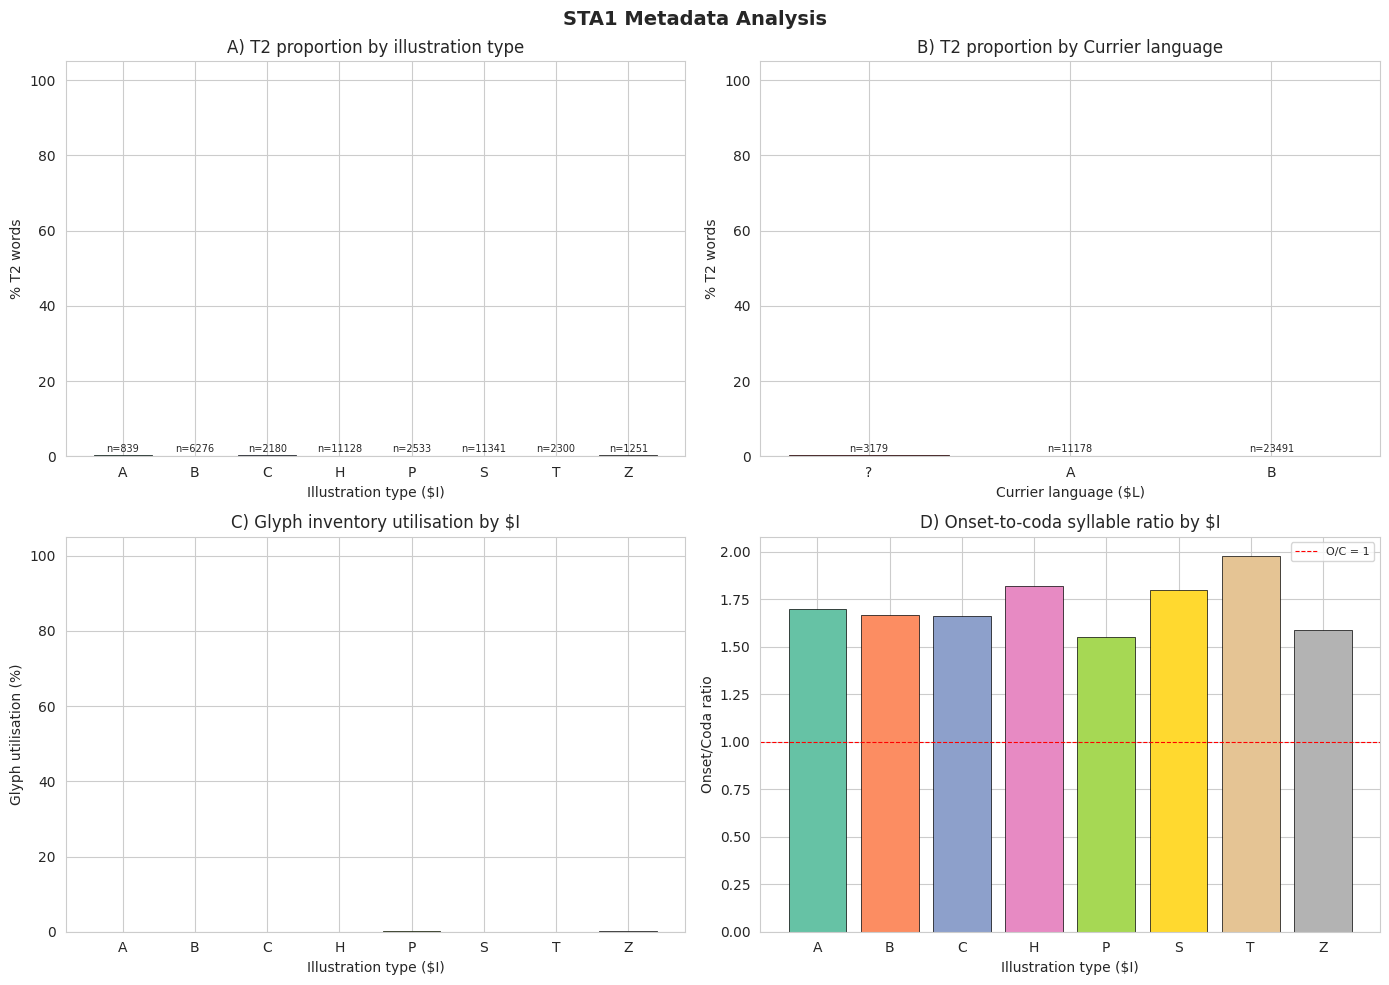

Figure saved to images/sta_metadata_analysis.png


In [67]:
# Cell 12 — 2x2 figure

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("STA1 Metadata Analysis", fontsize=14, fontweight="bold")

# Panel A: %T2 by $I type
ax = axes[0, 0]
itypes_sorted = sorted(metrics_by_I.keys())
pct_t2_vals = [metrics_by_I[k]["pct_OC"] for k in itypes_sorted]
n_words_vals = [metrics_by_I[k]["n_words"] for k in itypes_sorted]
colors_I = sns.color_palette("Set2", len(itypes_sorted))
bars = ax.bar(itypes_sorted, pct_t2_vals, color=colors_I, edgecolor="black", linewidth=0.5)
for bar, nw in zip(bars, n_words_vals):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"n={int(nw)}", ha="center", va="bottom", fontsize=7)
ax.set_xlabel("Illustration type ($I)")
ax.set_ylabel("% T2 words")
ax.set_title("A) T2 proportion by illustration type")
ax.set_ylim(0, 105)

# Panel B: %T2 by Currier language
ax = axes[0, 1]
ltypes_sorted = sorted(metrics_by_L.keys())
pct_t2_L = [metrics_by_L[k]["pct_OC"] for k in ltypes_sorted]
n_words_L = [metrics_by_L[k]["n_words"] for k in ltypes_sorted]
colors_L = sns.color_palette("Set1", len(ltypes_sorted))
bars = ax.bar(ltypes_sorted, pct_t2_L, color=colors_L, edgecolor="black", linewidth=0.5)
for bar, nw in zip(bars, n_words_L):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"n={int(nw)}", ha="center", va="bottom", fontsize=7)
ax.set_xlabel("Currier language ($L)")
ax.set_ylabel("% T2 words")
ax.set_title("B) T2 proportion by Currier language")
ax.set_ylim(0, 105)

# Panel C: Utilisation by $I
ax = axes[1, 0]
util_vals = [metrics_by_I[k]["utilisation"] for k in itypes_sorted]
ax.bar(itypes_sorted, util_vals, color=colors_I, edgecolor="black", linewidth=0.5)
ax.set_xlabel("Illustration type ($I)")
ax.set_ylabel("Glyph utilisation (%)")
ax.set_title("C) Glyph inventory utilisation by $I")
ax.set_ylim(0, 105)

# Panel D: O/C ratio by $I
ax = axes[1, 1]
oc_vals = [metrics_by_I[k]["oc_ratio"] for k in itypes_sorted]
ax.bar(itypes_sorted, oc_vals, color=colors_I, edgecolor="black", linewidth=0.5)
ax.axhline(1.0, color="red", linestyle="--", linewidth=0.8, label="O/C = 1")
ax.set_xlabel("Illustration type ($I)")
ax.set_ylabel("Onset/Coda ratio")
ax.set_title("D) Onset-to-coda syllable ratio by $I")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("images/sta_metadata_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved to images/sta_metadata_analysis.png")

## Conclusions

This notebook cross-tabulates the TP-P20 two-tier syllabic metrics against the three main STA1 metadata fields ($I, $L, $H).

**Key questions answered:**
1. Does syllabic structure vary by illustration type, Currier language, or scribal hand?
2. Do onset families distribute non-uniformly across metadata categories?
3. Do network communities from notebook 05 align with metadata partitions?

**Chi-squared tests summary:**
- Onset family x $I: see Cell 8
- Onset family x $L: see Cell 9
- Community x $I / $L / $H: see Cell 11

If all p-values are significant, the two-tier structure is metadata-sensitive (syllabic pools shift across sections). If not, the SilPart structure is universal across the manuscript.

In [68]:
# Cell 14 — Export results
import numpy as np

class NpEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.integer,)): return int(obj)
        if isinstance(obj, (np.floating,)): return float(obj)
        if isinstance(obj, (np.ndarray,)): return obj.tolist()
        if isinstance(obj, (np.bool_,)): return bool(obj)
        return super().default(obj)

export = {}

# Corpus stats
try:
    export['corpus'] = {
        'n_folios': len(folio_data),
        'n_words': len(all_words),
        'n_glyph_types': len(VOCAB),
    }
except: pass

# Tier distribution
try: export['tier_distribution'] = dict(tier_counts)
except: pass

# Metrics by $I, $L, $H
try: export['metrics_by_I'] = metrics_by_I
except: pass
try: export['metrics_by_L'] = metrics_by_L
except: pass
try: export['metrics_by_H'] = metrics_by_H
except: pass

# Chi-squared tests
chi2_results = {}
for name, vars in [
    ('onset_family_x_I', ('chi2_fam_I', 'p_fam_I', 'dof_fam_I')),
    ('onset_family_x_L', ('chi2_fam_L', 'p_fam_L', 'dof_fam_L')),
    ('community_x_I', ('chi2_comm_I', 'p_comm_I', 'dof_comm_I')),
    ('community_x_L', ('chi2_comm_L', 'p_comm_L', 'dof_comm_L')),
    ('community_x_H', ('chi2_comm_H', 'p_comm_H', 'dof_comm_H')),
]:
    try:
        chi2_results[name] = {
            'chi2': float(eval(vars[0])),
            'p': float(eval(vars[1])),
            'dof': int(eval(vars[2])),
        }
    except: pass
export['chi2_tests'] = chi2_results

# Onset families
try:
    export['onset_families'] = {
        'n_clusters': len(set(onset_family.values())) if onset_family else 0,
    }
except: pass

# Identifier uniqueness
try: export['identifier_uniqueness'] = id_uniqueness
except: pass

with open('resultados/sta_metadata_resultados.json', 'w') as f:
    json.dump(export, f, cls=NpEncoder, indent=2, ensure_ascii=False)

print(f"Exported: {list(export.keys())}")
for k, v in export.items():
    if isinstance(v, dict):
        print(f"  {k}: {len(v)} entries")
    else:
        print(f"  {k}: {v}")


Exported: ['corpus', 'tier_distribution', 'metrics_by_I', 'metrics_by_L', 'metrics_by_H', 'chi2_tests', 'onset_families', 'identifier_uniqueness']
  corpus: 3 entries
  tier_distribution: 3 entries
  metrics_by_I: 8 entries
  metrics_by_L: 3 entries
  metrics_by_H: 10 entries
  chi2_tests: 5 entries
  onset_families: 1 entries
  identifier_uniqueness: 8 entries
